## Universidad Panamericana Campus Aguascalientes
## Maestría en Inteligencia Artificial y Ciencia de Datos
### Procesamiento del Lenguaje Natural
**Proyecto Final:** Entre Alhóndigas, Besos y Momias

Alumno: Manuel Alejandro Serrano Macias

---

## Librerias

In [112]:
# Importar librerias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

import nltk
from nltk.tokenize import TweetTokenizer
from nltk.corpus import stopwords

from sklearn import preprocessing
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.decomposition import TruncatedSVD
from wordcloud import WordCloud

---
## Carga de datos

Cada hoja del Excel es un sitio turístico. Vamos a leer las 10 hojas y unirlas en una sola tabla, con una columna que diga de qué sitio es cada opinión.

In [113]:
# Cargamos las 10 hojas del Excel
hojas = pd.read_excel('Opiniones Tripadvisor_nlp2023.xlsx', sheet_name=None)

lista = []
for nombre_hoja in hojas:
  datos = hojas[nombre_hoja]
  datos['Sitio'] = nombre_hoja.rsplit(' ', 1)[0]  # 'Teatro Juárez 1,010' -> 'Teatro Juárez'
  lista += [datos]

df = pd.concat(lista, ignore_index=True)

# Nombres más cortos para las columnas que más usamos
df = df.rename(columns={'Género': 'Genero', 'Nacional ó Internacional': 'Origen',
                        'Título de la opinión': 'Titulo', 'Opinión': 'Opinion'})

# En género hay valores como ' Masculino' y 'masculino', los dejamos todos iguales
df['Genero'] = df['Genero'].str.strip().str.capitalize()

print(df.shape)
df.head()

(10462, 13)


,Genero,Edad,Origen,Calificación,Escala,Número de aportaciones,Titulo,Opinion,País,Idioma,Dispositivo,Fecha,Sitio
0,Femenino,64.0,Internacional,Muy bueno,4,175.0,"""Punto central""","""Basílica muy bien conservada, punto central en la ciudad , muy linda por dentro vale la pena darse una vuelta para conocer , alto significado religioso y arquitectónico.""",Colombia,Español,Móvil,2018-05-13,Basilica Colegiata
1,Masculino,59.0,Internacional,Excelente,5,306.0,"""The most important church in this colonial town full of history""","""The Basilica (Guanajuato does not have a Cathedral, it is situated in the nearby city of Leon) is truly imposing both during the day and when illuminated at night. It also has some lovely polychrome sculpture and a great organ.""",Colombia,Inglés,PC,2018-05-08,Basilica Colegiata
2,Femenino,26.0,Internacional,Excelente,5,106.0,"""Y uno de los símbolos de Guanajuato""","""Edificio de la iglesia amarilla es un abigarrado y nahu crear una más bella de Atocha. He venido a cabo mejor en frente de la misma Guanajuato es menor cuando se toman fotografías que gabolman menos una.""",Corea del Sur,Coreano,PC,2018-05-05,Basilica Colegiata
3,Masculino,50.0,Internacional,Excelente,5,62.0,"""Beautiful and a must see""","""A must see place in town and very nice to go inside and beautiful outside to take pics. in the center of town!""",Estados Unidos,Inglés,PC,2018-05-01,Basilica Colegiata
4,Femenino,55.0,Internacional,Regular,3,59.0,"""Nice""","""Not particularly impressive, but if you like historic buildings of any type, this is worth a walk-in.""",Estados Unidos,Inglés,PC,2018-04-29,Basilica Colegiata


---
## Exploración inicial

Revisamos:
1. Si hay valores vacíos
2. En qué idioma están escritas las opiniones
3. Cómo se reparten las edades de los turistas

In [114]:
# Revisamos cuántos valores vacíos hay en cada columna
df.isna().sum()

Genero                      0
Edad                      715
Origen                      0
Calificación                0
Escala                      0
Número de aportaciones      1
Titulo                      0
Opinion                     0
País                        0
Idioma                      0
Dispositivo                 0
Fecha                       0
Sitio                       0
dtype: int64

In [115]:
# Vemos en qué idioma se escribieron las opiniones
idiomas = df['Idioma'].value_counts()
print((idiomas / len(df) * 100).round(1).head()) # Porcentaje

Idioma
Español      62.4
Inglés       29.3
Portugués     2.1
Japonés       2.0
Francés       1.1
Name: count, dtype: float64


In [116]:
# Las opiniones de otros idiomas ya vienen traducidas al español, por ejemplo:
df[df['Idioma'] == 'Japonés']['Opinion'].iloc[0]

'"Es una famosa iglesia en Guanajuato. La noche es bella y se encienden. En las inmediaciones de la Universidad de Guanajuato, hay estudiantes japoneses. Ven lo que se recomienda quedarse."'

In [117]:
df[df['Idioma'] == 'Francés']['Opinion'].iloc[0]

'"Guanajuato y sus monumentos son una necesidad, es hermoso! Todo es para ver! Se necesitan al menos 4 días para ver todo a fondo."'

In [118]:
# Vemos cómo se reparten las edades para definir los rangos de edades
print(df['Edad'].describe().round(1))
print('Turistas de 29 años o menos:', (df['Edad'] <= 29).sum())
print('Turistas de 55 años o más:', (df['Edad'] >= 55).sum())

count    9747.0
mean       40.2
std        13.9
min        15.0
25%        29.0
50%        38.0
75%        50.0
max        81.0
Name: Edad, dtype: float64
Turistas de 29 años o menos: 2537
Turistas de 55 años o más: 1786


**Observaciones**
- **Valores vacíos**: Falta la edad en 715 opiniones y el número de aportaciones en una. El texto y la calificación están completos.
- **Idioma**: El 62. % de las opiniones se escribió en español y el 29.3% en inglés. El resto se escribió en otros idiomas (portugués, japonés, francés), pero su texto ya viene traducido al español.
- **Edades**: Los turistas tienen entre 15 y 81 años, con un promedio de 40. El 25% tiene 29 años o menos y el 25% tiene 50 años o más. Hay 2537 turistas de 29 años o menos y 1786 de 55 años o más.

---
## Tratamiento de datos

Con lo que vimos en la exploración, definimos cómo vamos a tratar los datos.

|  | Decisión |
|----------|--------------|
| Texto | Usamos el título junto con la opinión porque el título resume en pocas palabras lo que vivió el turista. |
| Idioma | Dejamos las opiniones en español y en inglés, y quitamos las stopwords de los dos idiomas. Cerca de 3 de cada 10 opiniones están en inglés (29.3%). Si las quitamos, perdemos a muchos turistas internacionales. |
| Limpieza | Pasamos todo a minúsculas, separamos las palabras con `TweetTokenizer` y nos quedamos con los tokens que son solo letras. Las opiniones vienen entre comillas y con mucho ruido. |
| Palabras de dominio | Quitamos las palabras que salen en todos los sitios (*guanajuato, lugar, visita*) y los nombres de los sitios (*momias, callejón, beso*). |
| Vocabulario | Usamos las 10000 palabras más frecuentes. |
| Polaridad | 4 y 5 es positiva, 3 es neutra, 1 y 2 es negativa. |
| Jóvenes | De 15 a 29 años (2537 opiniones). El 25% de los turistas tiene 29 años o menos. |
| Mayores | De 55 años en adelante (1786 opiniones). Es el 18% de los turistas con edad, suficiente para compararlo con los jóvenes (26%). |

Hay 715 opiniones sin edad. Solo las dejamos fuera cuando el análisis es por edad.

In [119]:
# Polaridad: 4 y 5 es positiva, 3 es neutra, 1 y 2 es negativa
df['Polaridad'] = 'neutra'
df.loc[df['Escala'] >= 4, 'Polaridad'] = 'positiva'
df.loc[df['Escala'] <= 2, 'Polaridad'] = 'negativa'

# Año y mes de cada opinión, para el análisis temporal
df['Año'] = df['Fecha'].dt.year
df['Mes'] = df['Fecha'].dt.month

# Los 6 grupos de turistas
grupos = {
  'Hombres': df['Genero'] == 'Masculino',
  'Mujeres': df['Genero'] == 'Femenino',
  'Nacionales': df['Origen'] == 'Nacional',
  'Internacionales': df['Origen'] == 'Internacional',
  'Jóvenes': df['Edad'].between(15, 29),
  'Mayores': df['Edad'] >= 55,
}

print(df['Polaridad'].value_counts())

Polaridad
positiva    8595
neutra      1441
negativa     426
Name: count, dtype: int64


---
## Preprocesamiento

Limpiamos el texto de cada opinión:
1. Pasamos todo a minúsculas
2. Separamos las palabras con `TweetTokenizer`
3. Nos quedamos con los tokens que son solo letras, removemos signos de puntuación, las comillas, los números y las URLs
4. Quitamos las stopwords de español e inglés, las palabras de dominio y las palabras de 2 letras o menos

In [120]:
nltk.download('stopwords', quiet=True)
tokenizer = TweetTokenizer()

# Stopwords de español y de inglés
stop = set(stopwords.words('spanish')) | set(stopwords.words('english'))

In [121]:
# Vemos las palabras más frecuentes quitando solo las stopwords de español e inglés
todas = []
for texto in df['Titulo'] + ' ' + df['Opinion']:
  todas += [t for t in tokenizer.tokenize(texto.lower()) if t.isalpha() and t not in stop and len(t) > 2]

nltk.FreqDist(todas).most_common(20)

[('guanajuato', 4168),
 ('lugar', 3503),
 ('ciudad', 2348),
 ('historia', 1845),
 ('vista', 1680),
 ('museo', 1581),
 ('visita', 1174),
 ('teatro', 1032),
 ('place', 1016),
 ('ver', 1015),
 ('momias', 993),
 ('puedes', 939),
 ('see', 933),
 ('museum', 926),
 ('visitar', 899),
 ('pena', 872),
 ('great', 850),
 ('city', 827),
 ('vale', 815),
 ('bien', 808)]

**Palabras de dominio.** Entre las palabras más frecuentes hay varias que no ayudan a distinguir un sitio de otro entonces quitamos:
1. Palabras generales que salen en todos los sitios, por ejemplo: *guanajuato, lugar, ciudad, visita, place, city*
2. Las palabras del nombre de cada sitio (*museo, momias, callejón, beso, teatro*), con su plural, sin acento y en inglés. Muchas opiniones de un sitio lo mencionan por su nombre, así que χ² nos regresaría el propio nombre como la palabra más relevante

Esto tiene un costo: *museo*, *teatro* e *hidalgo* son parte de un nombre, pero también se usan al hablar de otros sitios, como la Alhóndiga o el Jardín de la Unión.

In [122]:
palabras_dominio = {
  # Palabras generales que salen en todos los sitios
  'guanajuato', 'gto', 'lugar', 'lugares', 'visita', 'visitar', 'ciudad', 'place', 'city', 'visit',
  # Nombres de los sitios, con su plural, sin acento y en inglés
  'basilica', 'basílica', 'basilicas', 'basílicas', 'colegiata', 'mercado', 'mercados', 'hidalgo', 'market',
  'casa', 'diego', 'rivera', 'universidad', 'universidades', 'university',
  'alhondiga', 'alhóndiga', 'granaditas', 'teatro', 'teatros', 'theater', 'theatre', 'juarez', 'juárez',
  'jardin', 'jardín', 'jardines', 'union', 'unión', 'garden',
  'callejon', 'callejón', 'callejones', 'beso', 'kiss', 'alley',
  'monumento', 'monumentos', 'monument', 'pipila', 'pípila',
  'museo', 'museos', 'museum', 'museums', 'momias', 'momia', 'mummies', 'mummy',
}

stop.update(palabras_dominio)

def limpiar(texto):
  tokens = tokenizer.tokenize(texto.lower())
  # Nos quedamos con los tokens que son solo letras: así se van los signos, los números y las URLs
  return [t for t in tokens if t.isalpha() and t not in stop and len(t) > 2]

# Prueba
limpiar('"Visita obligada" "El Callejón del Beso es muy bonito, pero hay MUCHA gente!! 10/10"')

['obligada', 'bonito', 'mucha', 'gente']

In [123]:
# Juntamos el título con la opinión y limpiamos todas las opiniones
df['Tokens'] = (df['Titulo'] + ' ' + df['Opinion']).apply(limpiar)

# Vemos un ejemplo de antes y después
print('ANTES:  ', df['Titulo'][9000], df['Opinion'][9000])
print('DESPUÉS:', ' '.join(df['Tokens'][9000]))

ANTES:   "Momias" "Por 57 pesos no está nada mal, es una atracción muy importante en Guanajuato y además impresionante, te la recomiendo."
DESPUÉS: pesos mal atracción importante además impresionante recomiendo


---
## Actividad 1. Estadísticas básicas

### (a) Promedio y desviación estándar de la calificación

In [124]:
# Promedio y desviación estándar de la calificación (1 a 5) por sitio
calif = df.groupby('Sitio')['Escala'].agg(['count', 'mean', 'std']).round(2)
calif.columns = ['Opiniones', 'Promedio', 'Desv_est']
calif = calif.sort_values('Promedio', ascending=False)

# Guardamos este orden (del mejor al peor calificado)
sitios = list(calif.index)
calif

,Opiniones,Promedio,Desv_est
Sitio,,,
Teatro Juárez,1010,4.70,0.52
Universidad de Guanajuato,900,4.60,0.61
Jardín de la Unión,1134,4.59,0.61
Basilica Colegiata,560,4.50,0.67
Alhóndiga,930,4.45,0.75
Monumento Pípila,1620,4.38,0.77
Casa de Diego Rivera,698,4.24,0.80
Callejón del Beso,1360,4.00,0.97
Mercado Hidalgo,600,3.95,0.95


### (b) Longitud de las opiniones en palabras

In [125]:
# Contamos las palabras de cada opinión original (antes de limpiarla)
df['Num_palabras'] = df['Opinion'].str.split().str.len()

longitud = df.groupby('Sitio')['Num_palabras'].agg(['mean', 'std']).round(1)
longitud.columns = ['Promedio', 'Desv_est']
longitud.loc[sitios]

,Promedio,Desv_est
Sitio,,
Teatro Juárez,41.5,27.1
Universidad de Guanajuato,35.4,20.1
Jardín de la Unión,43.1,37.0
Basilica Colegiata,39.7,29.5
Alhóndiga,46.5,34.0
Monumento Pípila,47.4,35.9
Casa de Diego Rivera,49.3,30.5
Callejón del Beso,45.5,32.9
Mercado Hidalgo,45.6,33.5


### (c) Histogramas de edades por sitio

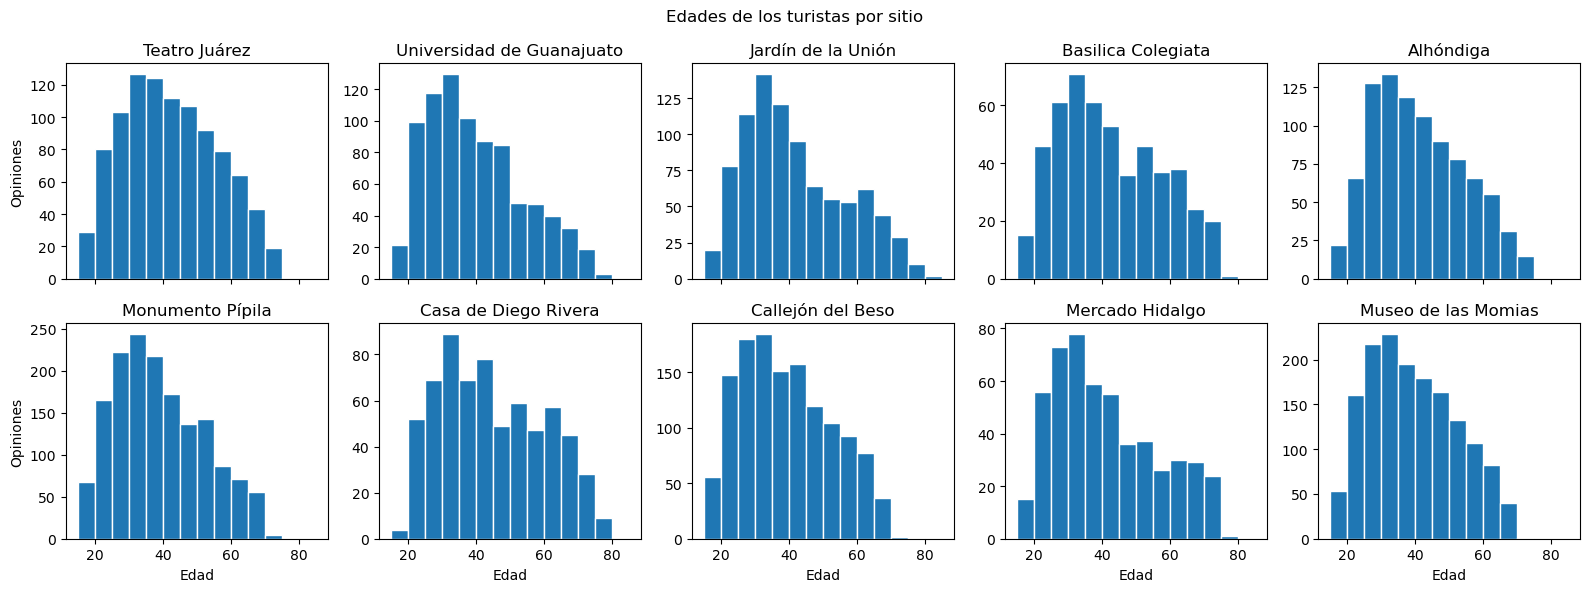

In [126]:
# Un histograma por sitio, con las edades agrupadas de 5 en 5 años
fig, axes = plt.subplots(2, 5, figsize=(16, 6), sharex=True)
for ax, sitio in zip(axes.flat, sitios):
  edades = df[df['Sitio'] == sitio]['Edad'].dropna()
  ax.hist(edades, bins=range(15, 90, 5), edgecolor='white')
  ax.set_title(sitio)

for ax in axes[:, 0]:
  ax.set_ylabel('Opiniones')
for ax in axes[1]:
  ax.set_xlabel('Edad')

fig.suptitle('Edades de los turistas por sitio')
plt.tight_layout()
plt.show()

In [127]:
# Edad promedio y porcentaje de jóvenes y mayores por sitio (solo opiniones que tienen edad)
con_edad = df[df['Edad'].notna()]

edad = pd.DataFrame({
  'Edad promedio': con_edad.groupby('Sitio')['Edad'].mean(),
  '% Jóvenes (15 a 29)': (con_edad['Edad'] <= 29).groupby(con_edad['Sitio']).mean() * 100,
  '% Mayores (55 o más)': (con_edad['Edad'] >= 55).groupby(con_edad['Sitio']).mean() * 100,
})
edad.loc[sitios].round(1)

,Edad promedio,% Jóvenes (15 a 29),% Mayores (55 o más)
Sitio,,,
Teatro Juárez,41.8,21.7,20.9
Universidad de Guanajuato,39.3,28.6,17.0
Jardín de la Unión,41.4,23.8,22.5
Basilica Colegiata,41.9,24.0,23.6
Alhóndiga,40.7,23.7,18.4
Monumento Pípila,38.4,28.7,13.7
Casa de Diego Rivera,44.3,19.1,28.4
Callejón del Beso,38.8,29.3,16.0
Mercado Hidalgo,40.7,27.7,21.2


### (d) Turistas nacionales e internacionales por sitio

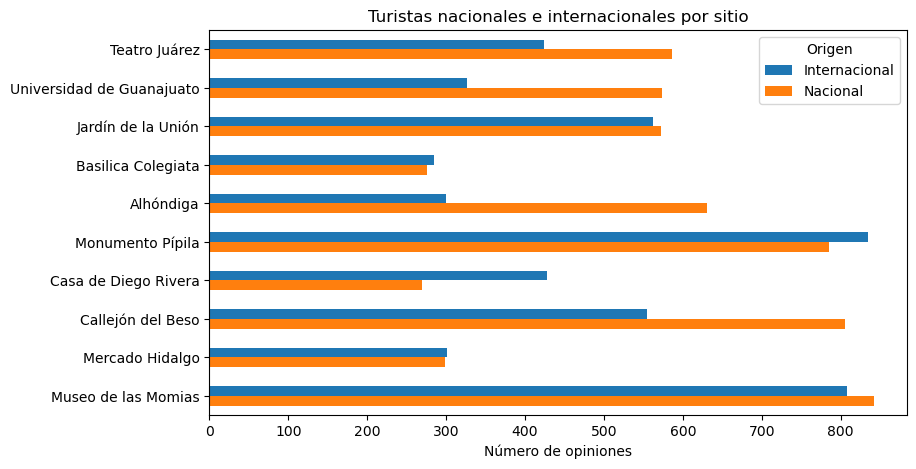

Origen,Internacional,Nacional,% Internacional
Sitio,,,
Teatro Juárez,424,586,42.0
Universidad de Guanajuato,327,573,36.3
Jardín de la Unión,562,572,49.6
Basilica Colegiata,284,276,50.7
Alhóndiga,300,630,32.3
Monumento Pípila,835,785,51.5
Casa de Diego Rivera,428,270,61.3
Callejón del Beso,554,806,40.7
Mercado Hidalgo,301,299,50.2


In [128]:
# Contamos las opiniones de turistas nacionales e internacionales en cada sitio
origen = pd.crosstab(df['Sitio'], df['Origen']).loc[sitios]

origen.plot(kind='barh', figsize=(9, 5))
plt.gca().invert_yaxis()  # para que el orden sea el mismo de las tablas
plt.title('Turistas nacionales e internacionales por sitio')
plt.xlabel('Número de opiniones')
plt.ylabel('')
plt.show()

origen['% Internacional'] = (origen['Internacional'] / origen.sum(axis=1) * 100).round(1)
origen

### (e) Dos estadísticas más

**Polaridad por sitio.** Qué porcentaje de las opiniones de cada sitio son positivas, neutras o negativas. Nos sirve para ver en qué sitios los turistas no se ponen de acuerdo.

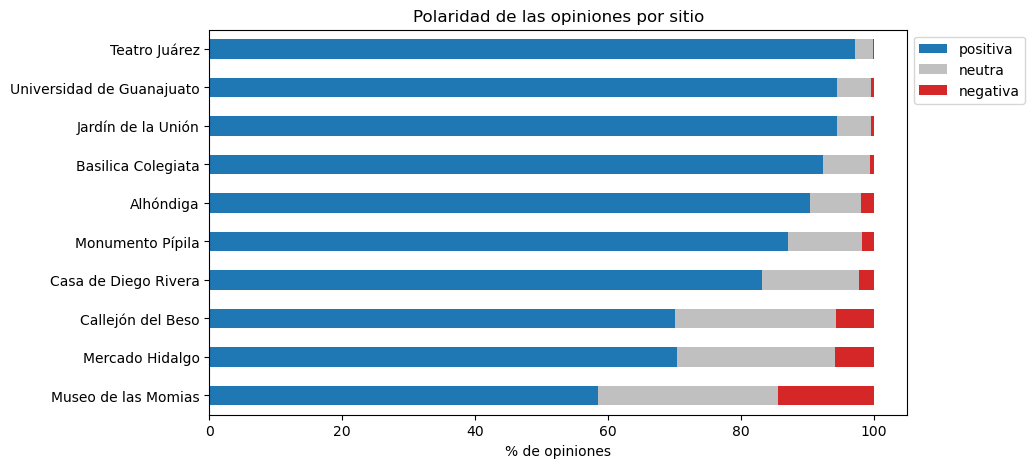

Polaridad,positiva,neutra,negativa
Sitio,,,
Teatro Juárez,97.2,2.7,0.1
Universidad de Guanajuato,94.4,5.1,0.4
Jardín de la Unión,94.5,5.0,0.4
Basilica Colegiata,92.3,7.1,0.5
Alhóndiga,90.4,7.6,1.9
Monumento Pípila,87.2,11.0,1.8
Casa de Diego Rivera,83.2,14.5,2.3
Callejón del Beso,70.1,24.2,5.7
Mercado Hidalgo,70.3,23.8,5.8


In [129]:
# Estos colores los usamos en todas las gráficas de polaridad
polaridades = ['positiva', 'neutra', 'negativa']
colores = ['tab:blue', 'silver', 'tab:red']

# Porcentaje de opiniones positivas, neutras y negativas de cada sitio
pol = pd.crosstab(df['Sitio'], df['Polaridad'], normalize='index').loc[sitios, polaridades] * 100

pol.plot(kind='barh', stacked=True, color=colores, figsize=(9, 5))
plt.gca().invert_yaxis()
plt.title('Polaridad de las opiniones por sitio')
plt.xlabel('% de opiniones')
plt.ylabel('')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))  # leyenda afuera para que no tape las barras
plt.show()

pol.round(1)

**Calificación promedio por grupo de turistas.** Comparamos la calificación de cada sitio entre los 6 grupos. Nos sirve para ver si un sitio le gusta más a un grupo que a otro.

In [130]:
# Calificación promedio de cada sitio para cada grupo de turistas
prom_grupo = pd.DataFrame()
for grupo in grupos:
  prom_grupo[grupo] = df[grupos[grupo]].groupby('Sitio')['Escala'].mean()

prom_grupo.loc[sitios].round(2)

,Hombres,Mujeres,Nacionales,Internacionales,Jóvenes,Mayores
Sitio,,,,,,
Teatro Juárez,4.68,4.73,4.77,4.61,4.75,4.70
Universidad de Guanajuato,4.57,4.64,4.71,4.42,4.65,4.61
Jardín de la Unión,4.57,4.62,4.60,4.58,4.58,4.58
Basilica Colegiata,4.44,4.58,4.50,4.50,4.48,4.50
Alhóndiga,4.46,4.44,4.43,4.50,4.45,4.55
Monumento Pípila,4.34,4.43,4.33,4.43,4.41,4.33
Casa de Diego Rivera,4.24,4.25,4.34,4.18,4.22,4.15
Callejón del Beso,3.95,4.04,4.09,3.85,4.09,4.01
Mercado Hidalgo,3.89,4.01,3.87,4.03,4.03,3.99


**Observaciones**
- **Calificación**: El Teatro Juárez es el mejor calificado (4.70) y donde los turistas están más de acuerdo (desviación de 0.52). El Museo de las Momias es el peor calificado (3.68) y el que tiene la desviación más alta (1.14).
- **Longitud**: Las opiniones más largas son las del Museo de las Momias (58 palabras en promedio) y las más cortas las de la Universidad (35 palabras).
- **Edades**: En todos los sitios el rango con más turistas es el de 30 a 34 años. El Callejón del Beso, el Pípila y la Universidad tienen más jóvenes 29% y la Casa de Diego Rivera más mayores 28%.
- **Origen**: La Casa de Diego Rivera es el sitio más internacional 61% y la Alhóndiga el más nacional, 68% de turistas nacionales.
- **Polaridad**: Solo el 58.5% de las opiniones del Museo de las Momias son positivas. Le siguen el Callejón del Beso y el Mercado Hidalgo con 70%. En el Teatro Juárez son el 97%.
- **Grupos**: Las diferencias entre grupos son pequeñas. Las más grandes están en la Universidad (4.71 nacionales contra 4.42 internacionales) y en el Callejón del Beso (4.09 contra 3.85).

---
## Actividad 2. Palabras más relevantes por sitio con χ²

Vamos a buscar las 50 palabras que mejor describen a cada sitio:

1. Armamos el vocabulario con las 10000 palabras más frecuentes (`FreqDist` y `sortFreqDist`)
2. Construimos la bolsa de palabras con `build_bow_tr` y la convertimos a TF-IDF con norma L2
3. Para cada sitio aplicamos χ² con `SelectKBest`, comparando sus opiniones contra las de los otros 9 sitios
4. Dibujamos una nube por sitio con sus 50 mejores palabras

In [131]:
# Funciones que hicimos en las prácticas de tarea
def sortFreqDist(freqdict):
  aux = [(freqdict[key], key) for key in freqdict]
  aux.sort()
  aux.reverse()
  return aux

def vocabulario(lista_tokens, tam):
  # Juntamos todos los tokens y nos quedamos con los más frecuentes
  corpus_palabras = []
  for tokens in lista_tokens:
    corpus_palabras += tokens
  fdist = nltk.FreqDist(corpus_palabras)
  V = sortFreqDist(fdist)[:tam]

  dict_indices = dict()
  count = 0
  for weight, word in V:
    dict_indices[word] = count
    count += 1
  return V, dict_indices

def build_bow_tr(lista_tokens, V, dict_indices):
  BOW = np.zeros((len(lista_tokens), len(V)), dtype=np.float32)
  count_doc = 0
  for tokens in lista_tokens:
    fdist_doc = nltk.FreqDist(tokens)
    for word in fdist_doc:
      if word in dict_indices:
        BOW[count_doc, dict_indices[word]] = fdist_doc[word]
    count_doc += 1
  return BOW

**TF-IDF.** En las prácticas que hicimos de tarea la bolsa de palabras era de conteos. Aquí la convertimos a TF-IDF:

- **TF**: cuántas veces aparece la palabra en la opinión
- **IDF**: `log(N / df)`, donde `N` es el total de opiniones y `df` es en cuántas opiniones aparece la palabra. Las palabras que salen en casi todas las opiniones pesan menos

Al final normalizamos cada opinión con L2, como lo hicimos con TCOR en la Práctica 3.

In [132]:
def tfidf_l2(BOW):
  N = BOW.shape[0]
  df_palabra = (BOW > 0).sum(axis=0)  # en cuántas opiniones aparece cada palabra
  idf = np.log(N / df_palabra).astype(np.float32)
  return preprocessing.normalize(BOW * idf, norm='l2')

# Construimos la matriz una sola vez, con todas las opiniones
V, dict_indices = vocabulario(df['Tokens'], 10000)
palabras = [word for weight, word in V]

TFIDF = tfidf_l2(build_bow_tr(df['Tokens'], V, dict_indices))
TFIDF.shape

(10462, 10000)

**χ² por sitio.** χ² nos dice qué tan relacionada está una palabra con un sitio. El detalle es que también le da un valor alto a las palabras que un sitio casi no usa. Por ejemplo, *vista* salía entre las mejores del Museo de las Momias, porque ahí casi nadie habla de la vista. Por eso nos quedamos solo con las palabras que el sitio usa más que los demás.

In [133]:
def top_chi2(X, y, palabras, k=50):
  feats = SelectKBest(chi2, k='all')
  feats.fit(X, y)
  scores = feats.scores_.copy()

  # Quitamos las palabras que el sitio usa menos que el resto de los sitios
  scores[X[y].mean(axis=0) < X[~y].mean(axis=0)] = 0

  best = np.argsort(scores)[::-1][:k]
  best_dict = {palabras[idx]: scores[idx] for idx in best}
  return best_dict

# Para cada sitio, sus opiniones contra las de los demás
nubes = {}
for sitio in sitios:
  y = (df['Sitio'] == sitio).values
  nubes[sitio] = top_chi2(TFIDF, y, palabras)

# Las 10 palabras más relevantes de cada sitio
pd.DataFrame({sitio: list(nubes[sitio])[:10] for sitio in sitios}).T

,0,1,2,3,4,5,6,7,8,9
Teatro Juárez,hermoso,interior,porfirio,joya,porfiriato,performance,artes,acústica,díaz,decoración
Universidad de Guanajuato,edificio,arquitectura,escalinata,escaleras,escalinatas,escalera,escalones,estudiar,imponente,stairs
Jardín de la Unión,restaurantes,restaurants,music,mariachis,mariachi,bares,trees,plaza,música,square
Basilica Colegiata,iglesia,church,amarillo,iglesias,misa,templo,virgen,mass,paz,churches
Alhóndiga,independencia,historia,murales,history,méxico,independence,salas,revolution,histórico,domingos
Monumento Pípila,vista,view,funicular,mirador,panorámica,views,subir,teleférico,statue,estatua
Casa de Diego Rivera,obras,work,art,home,house,frida,works,artista,pintor,artists
Callejón del Beso,leyenda,pareja,romántico,amor,escalón,balcón,foto,tercer,callejoneada,romeo
Mercado Hidalgo,comida,food,carnitas,artesanías,dulces,comprar,stalls,frutas,precios,eiffel
Museo de las Momias,cuerpos,bodies,creepy,dead,cadáveres,interesante,momificados,proceso,muerte,mummified


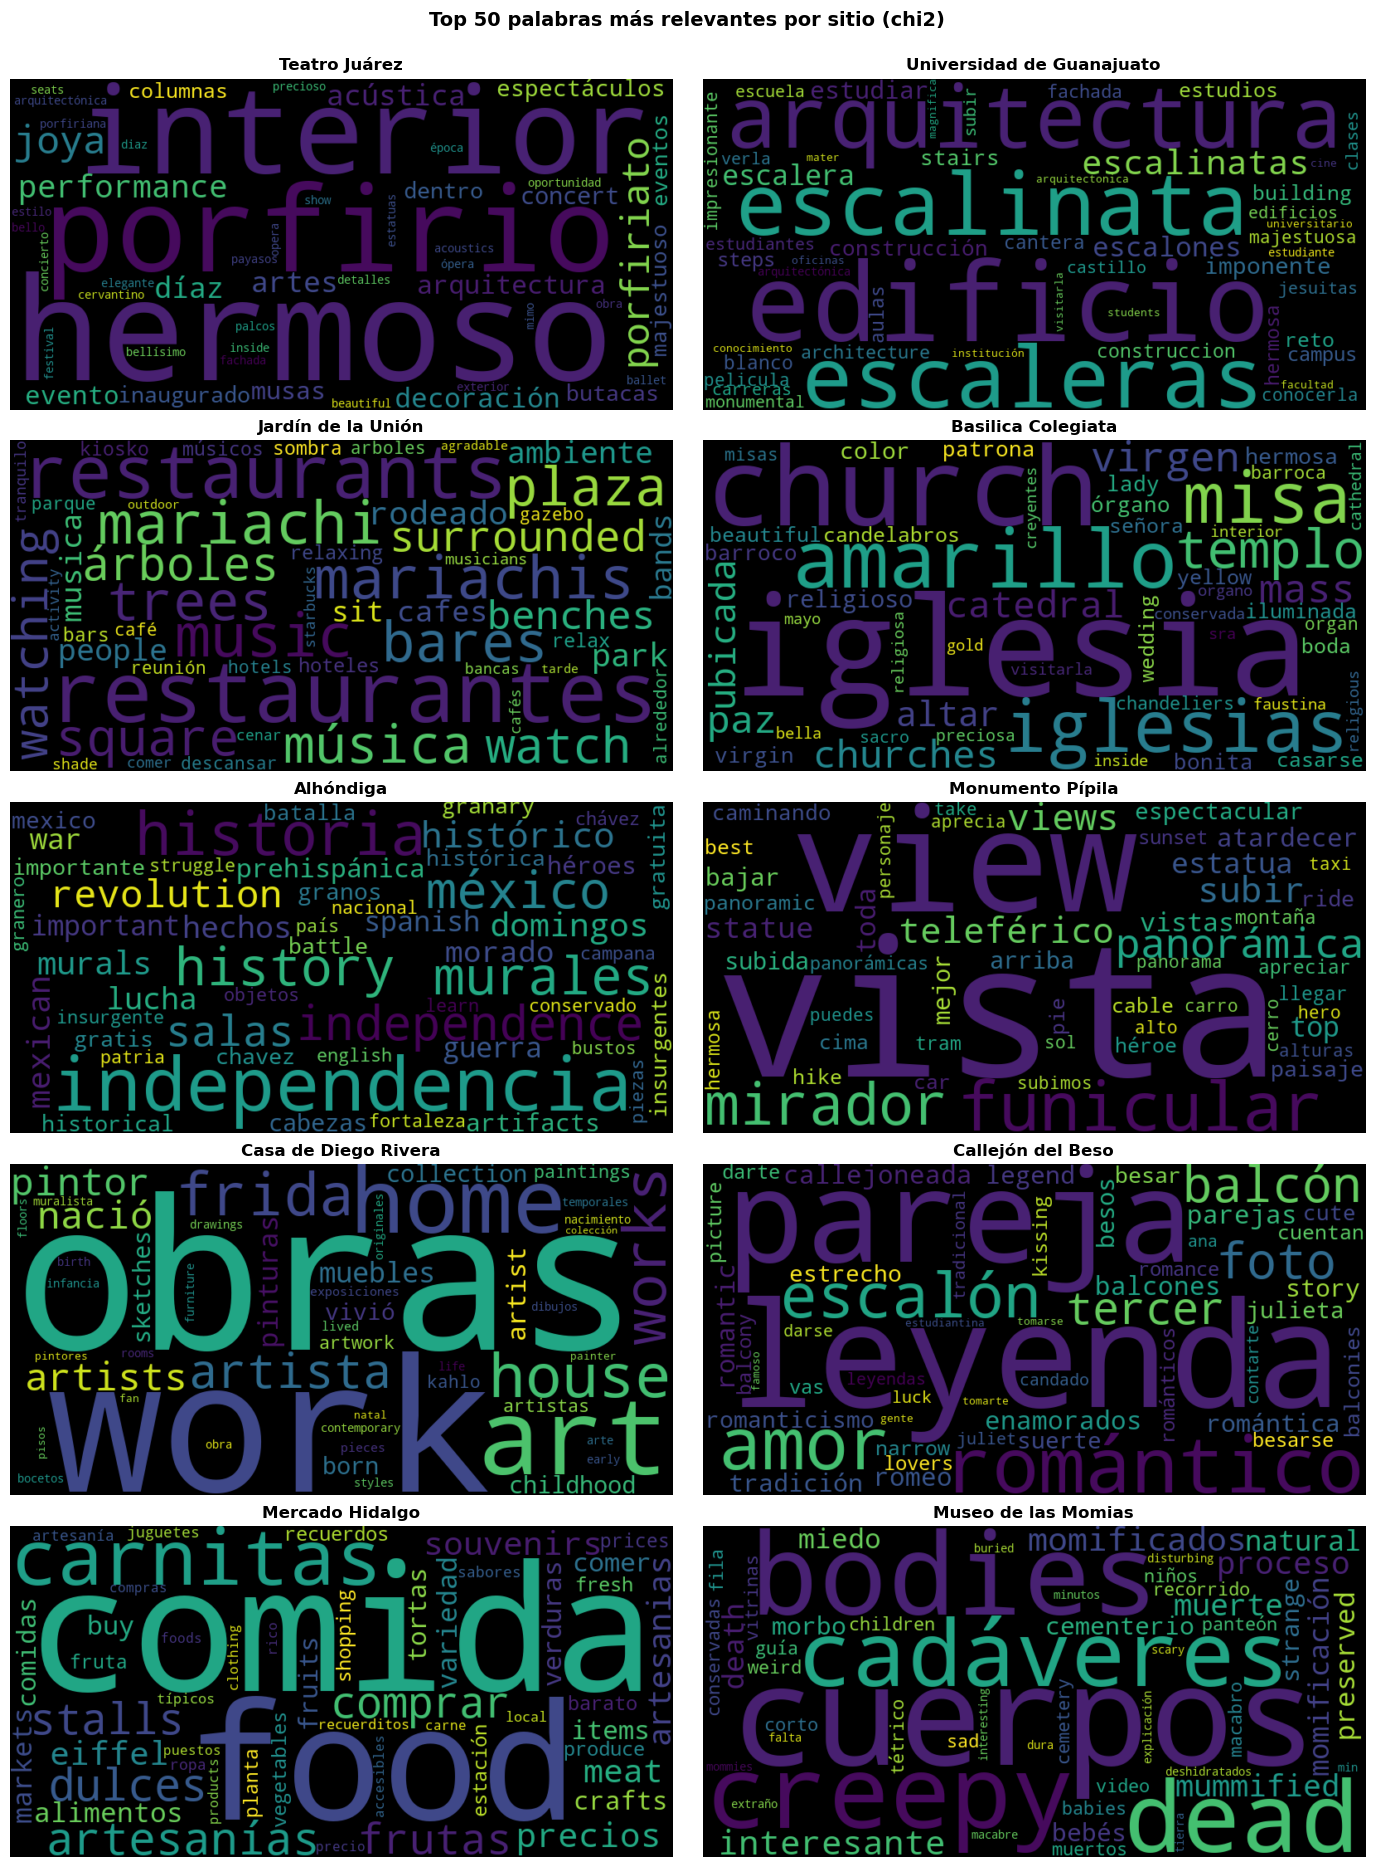

In [134]:
def dibujar_nubes(nubes, titulo):
  # Una nube por sitio; el tamaño de cada palabra depende de su valor de chi2
  fig, axes = plt.subplots(5, 2, figsize=(14, 19))
  for ax, sitio in zip(axes.flat, nubes):
    wordcloud = WordCloud(width=800, height=400, background_color="black", random_state=42).generate_from_frequencies(nubes[sitio])
    ax.imshow(wordcloud, interpolation='bilinear')
    ax.set_title(sitio, fontweight='bold')
    ax.axis('off')
  fig.suptitle(titulo, fontsize=14, fontweight='bold')
  plt.tight_layout(rect=(0, 0, 1, 0.98))
  plt.show()

dibujar_nubes(nubes, 'Top 50 palabras más relevantes por sitio (chi2)')

**Observaciones**
- Las palabras de cada nube sí describen al sitio: *vista, funicular, mirador* en el Pípila, *leyenda, pareja, romántico* en el Callejón del Beso y *comida, carnitas, artesanías* en el Mercado Hidalgo.
- Aparecen juntas las palabras en español y en inglés del mismo tema (*iglesia / church*, *vista / view*, *historia / history*).
- En el Museo de las Momias, junto a *interesante*, salen palabras como (*creepy, bodies, cuerpos, cadáveres, dead*).

---
## Actividad 3. Tópicos con LSA

**¿Qué es LSA?** El Análisis Semántico Latente busca temas escondidos en un conjunto de textos. Toma la matriz TF-IDF (cada fila es una opinión y cada columna es una palabra) y la descompone con SVD:

$$X \approx U \, \Sigma \, V^T$$

| Matriz | Qué nos dice |
|--------|--------------|
| **U** | Qué tanto tiene cada opinión de cada tópico |
| **Σ** | Qué tan importante es cada tópico |
| **Vᵀ** | Qué tanto pesa cada palabra en cada tópico |

Si nos quedamos solo con los 3 valores más grandes de Σ, obtenemos los 3 tópicos más importantes. Las 10 palabras con más peso en cada fila de Vᵀ son las que describen al tópico.

Usamos `TruncatedSVD` de sklearn, que es una de las opciones que sugiere el enunciado. La matriz de entrada es la TF-IDF con L2 de la Actividad 2 (10462 opiniones × 1,000 palabras). Para cada sitio y cada grupo tomamos solo las filas de sus opiniones.

In [135]:
def topicos_lsa(X, palabras, n_topicos=3, n_palabras=10):
  # LSA: SVD truncada sobre la matriz TF-IDF
  svd = TruncatedSVD(n_components=n_topicos, random_state=42)
  svd.fit(X)

  topicos = []
  for componente in svd.components_:
    best = np.argsort(componente)[::-1][:n_palabras]  # las palabras con más peso en el tópico
    topicos += [', '.join([palabras[idx] for idx in best])]
  return topicos

# Probamos con un caso: las mujeres que opinaron del Museo de las Momias
filas = ((df['Sitio'] == 'Museo de las Momias') & grupos['Mujeres']).values
topicos_lsa(TFIDF[filas], palabras)

['interesante, cuerpos, ver, bien, guía, recorrido, personas, explicación, gente, pena',
 'interesting, bodies, see, creepy, dead, people, like, really, tour, worth',
 'interesante, cuerpos, momificados, muerte, cadáveres, diferente, miedo, ver, experiencia, conservan']

In [136]:
# Ahora los 10 sitios con sus 6 grupos: 60 combinaciones, 3 tópicos cada una
lsa = []
for sitio in sitios:
  for grupo in grupos:
    filas = ((df['Sitio'] == sitio) & grupos[grupo]).values
    topicos = topicos_lsa(TFIDF[filas], palabras)
    for i in range(3):
      lsa += [[sitio, grupo, filas.sum(), i + 1, topicos[i]]]

lsa = pd.DataFrame(lsa, columns=['Sitio', 'Grupo', 'Opiniones', 'Tópico', 'Palabras'])
print('Grupo más pequeño:', lsa['Opiniones'].min(), 'opiniones')

Grupo más pequeño: 110 opiniones


In [137]:
# Una tabla por sitio con los 3 tópicos de cada grupo
pd.set_option('display.max_colwidth', None)

for sitio in sitios:
  print(sitio)
  display(lsa[lsa['Sitio'] == sitio].set_index(['Grupo', 'Opiniones', 'Tópico'])[['Palabras']])

Teatro Juárez


Palabras
Grupo           Opiniones Tópico                                                                                                         
Hombres         554       1                      hermoso, arquitectura, interior, bonito, dentro, vale, pena, méxico, impresionante, joya
                          2                          beautiful, inside, building, see, outside, amazing, architecture, worth, tour, night
                          3                  hermoso, visitarlo, bonito, enfrente, iluminado, cerca, escuchar, cómodo, recinto, historias
Mujeres         456       1                   hermoso, arquitectura, dentro, pena, vale, historia, bello, entrar, interior, impresionante
                          2                       beautiful, see, building, inside, performance, amazing, architecture, worth, time, wish
                          3                        hermoso, iluminación, edificio, divino, unirse, nocturna, cuidado, día, noche, francia
Nacionales      586       1                            hermoso, arquitectura, dentro, pena, vale, interior, bello, historia, bonito, joya
                          2                   hermoso, visitarlo, pena, vale, cuidado, sitio, iluminación, definitivamente, decir, unirse
                          3       arquitectura, hermoso, joya, iluminación, porfiriato, hermosa, noche, precioso, acabados, callejoneadas
Internacionales 424       1                   beautiful, inside, building, see, performance, worth, amazing, architecture, night, outside
                          2                        hermoso, interior, arquitectura, exterior, edificio, pena, vale, bonito, precioso, ver
                          3                      beautiful, inside, amazing, outside, interior, shows, exterior, structure, saw, statutes
Jóvenes         212       1                            hermoso, dentro, arquitectura, vale, pena, visitarlo, noche, bello, bonito, entrar
                          2                        hermoso, escuchar, noche, visitarlo, gusto, dejar, restaurantes, tomen, historias, aún
                          3                          beautiful, inside, architecture, night, see, amazing, gorgeous, building, worth, day
Mayores         205       1                      hermoso, interior, arquitectura, beautiful, building, vale, bonito, pena, méxico, entrar
                          2                   beautiful, building, inside, amazing, see, architecture, worth, concert, great, performance
                          3                      hermoso, interior, iluminación, edificio, cómodo, puedo, dudas, acabados, día, sumamente

Universidad de Guanajuato


Palabras
Grupo           Opiniones Tópico                                                                                                           
Hombres         484       1                 edificio, arquitectura, hermosa, escalinata, escaleras, impresionante, subir, vista, vale, pena
                          2                                building, stairs, steps, beautiful, climb, architecture, great, nice, main, view
                          3                   edificio, escalera, bonito, hermoso, puede, imponente, estudiantes, blanco, histórico, estilo
Mujeres         416       1        edificio, arquitectura, escaleras, hermosa, hermoso, impresionante, subir, vista, imponente, escalinatas
                          2                      edificio, hermoso, precioso, bello, building, beautiful, escalera, principal, hacia, suben
                          3                              building, beautiful, stairs, architecture, steps, view, top, great, amazing, worth
Nacionales      573       1       edificio, arquitectura, escaleras, hermosa, subir, impresionante, escalinata, vista, escalones, imponente
                          2             edificio, hermoso, bonito, escalinatas, cantera, bello, emblemático, histórico, fachada, escalinata
                          3                                  escaleras, hermosa, subir, vista, foto, escalinata, vale, fachada, pena, fotos
Internacionales 327       1                               building, stairs, beautiful, steps, architecture, great, climb, nice, view, worth
                          2            edificio, escalera, hermosa, arquitectura, hermoso, impresionante, escaleras, gran, imponente, vista
                          3                            steps, beautiful, stands, photo, steep, town, viewed, architecture, views, buildings
Jóvenes         238       1                  edificio, arquitectura, hermosa, escaleras, subir, vista, impresionante, escalones, vale, pena
                          2               edificio, impresionante, hermoso, bello, precioso, méxico, majestuoso, espectacular, puerta, vale
                          3                arquitectura, espectacular, pena, bonita, vale, impresionante, escalinata, además, entrar, gusto
Mayores         141       1               edificio, escalera, escaleras, hermoso, estudiantes, escalinata, gran, puede, arquitectura, noche
                          2                          building, stairs, architecture, steps, view, inside, climb, worth, buildings, students
                          3                                 escalera, gran, graduados, españa, espíritu, aprecia, sube, roca, luchas, borde

Jardín de la Unión


Palabras
Grupo           Opiniones Tópico                                                                                                 
Hombres         624       1             restaurants, people, plaza, restaurantes, music, great, square, watching, watch, mariachi
                          2               restaurantes, ambiente, bonito, bares, rodeado, música, centro, comer, agradable, pasar
                          3           plaza, restaurantes, centro, principal, árboles, sombra, hoteles, alrededor, rodeada, bares
Mujeres         510       1       restaurantes, restaurants, people, plaza, music, música, watch, alrededor, agradable, disfrutar
                          2            restaurantes, música, agradable, alrededor, disfrutar, bares, hermoso, pasar, lindo, noche
                          3              restaurantes, plaza, bares, alrededor, reunión, punto, lindo, hoteles, centro, encuentro
Nacionales      572       1          restaurantes, ambiente, música, agradable, bares, bonito, pasar, comer, disfrutar, alrededor
                          2        restaurantes, hoteles, plaza, bares, reunión, punto, centro, callejoneadas, alrededor, corazón
                          3           bonito, comer, alrededor, pequeño, rodeado, restaurantes, caminar, descansar, cuidado, bien
Internacionales 562       1                        restaurants, people, music, watch, square, great, sit, watching, trees, around
                          2             plaza, restaurantes, mariachis, centro, bares, árboles, música, noche, alrededor, rodeado
                          3                   restaurants, square, trees, surrounded, beautiful, lovely, bars, park, around, lots
Jóvenes         212       1               restaurantes, pasar, comer, bares, música, bonito, alrededor, disfrutar, café, ambiente
                          2              restaurants, surrounded, music, people, beautiful, great, benches, around, sit, mariachi
                          3                          pasar, comer, café, disfrutar, caminar, rato, musica, tarde, escuchar, cenar
Mayores         200       1                           restaurants, people, trees, music, plaza, watch, great, lovely, one, center
                          2          restaurantes, música, ambiente, corazón, plaza, centro, agradable, hoteles, mariachis, noche
                          3                         music, plaza, dance, bands, mariachi, activity, center, evening, great, loved

... (10 outputs left out)

Mercado Hidalgo


Palabras
Grupo           Opiniones Tópico                                                                                                
Hombres         328       1         comida, artesanías, comprar, comer, recuerdos, variedad, precios, precio, alimentos, puestos
                          2                         food, stalls, souvenirs, buy, local, mexican, building, locals, great, floor
                          3           comida, típico, artesanías, encontrar, puestos, juguetes, típica, dulces, ropa, souvenires
Mujeres         272       1               comida, artesanías, dulces, comprar, comer, precios, recuerdos, variedad, precio, buen
                          2                             food, great, buy, stalls, souvenirs, shopping, local, items, lots, fresh
                          3          comer, barato, comida, recuerdos, enchiladas, mineras, comprar, souvenirs, variedad, fondas
Nacionales      299       1               comida, artesanías, dulces, comprar, comer, variedad, precios, precio, recuerdos, buen
                          2             comer, rico, barato, comprar, recuerdos, precios, opción, quieres, accesibles, desayunar
                          3             comida, rica, típico, enchiladas, souvenirs, buena, típica, variedad, precio, encuentras
Internacionales 301       1                            food, stalls, buy, souvenirs, great, local, locals, lots, building, items
                          2                comida, comprar, recuerdos, piso, alimentos, artesanías, comer, frutas, tiendas, aquí
                          3                            stalls, food, indoor, touristy, stuff, lots, average, worth, stall, floor
Jóvenes         144       1             comida, artesanías, comer, comprar, variedad, dulces, precios, precio, recuerdos, barato
                          2                               food, buy, souvenirs, stalls, items, eat, local, shopping, great, lots
                          3       comida, artesanías, precio, dulces, mineras, enchiladas, típico, regular, tradicional, popular
Mayores         110       1                      food, stalls, everything, souvenirs, meat, lots, clothing, find, fresh, vendors
                          2                  recuerdos, comida, aquí, piso, comprar, artesanías, venden, puestos, gran, variedad
                          3                               stalls, selling, lots, vendors, food, fresh, meat, fruit, saw, average

Museo de las Momias


Palabras
Grupo           Opiniones Tópico                                                                                                                     
Hombres         871       1                                                  interesante, cuerpos, ver, recorrido, bien, guía, vez, pena, vale, niños
                          2                                           interesting, bodies, dead, see, people, like, creepy, one, mummified, preserved
                          3       cuerpos, momificados, deshidratados, natural, conservados, cadáveres, macabro, proceso, naturalmente, impresionante
Mujeres         779       1                                      interesante, cuerpos, ver, bien, guía, recorrido, personas, explicación, gente, pena
                          2                                                 interesting, bodies, see, creepy, dead, people, like, really, tour, worth
                          3                       interesante, cuerpos, momificados, muerte, cadáveres, diferente, miedo, ver, experiencia, conservan
Nacionales      842       1                                            interesante, recorrido, ver, cuerpos, guía, vez, bien, fila, hace, explicación
                          2                        cuerpos, interesante, momificados, ver, deshidratados, proceso, muerte, tierra, cadáveres, muertos
                          3                                         interesante, fila, pena, vale, alta, temporada, conocer, horas, conservadas, guía
Internacionales 808       1                                               interesting, bodies, see, dead, creepy, people, like, one, preserved, worth
                          2                                  cuerpos, interesante, bien, ver, impresionante, cadáveres, niños, vale, cementerio, pena
                          3                                        bodies, dead, people, mummified, babies, burial, buried, soil, preserved, families
Jóvenes         430       1                                         interesante, recorrido, guía, cuerpos, bien, ver, fila, historia, falta, personas
                          2                                              interesting, see, like, bodies, seeing, well, worth, must, creepy, preserved
                          3                                               fila, recorrido, espera, hora, entrar, minutos, corto, pena, esperaba, dura
Mayores         230       1                                             dead, bodies, interesting, see, display, well, creepy, like, would, mummified
                          2                               cuerpos, interesante, ver, bien, cadáveres, personas, información, niños, muertos, obligada
                          3                                             dead, bodies, people, mummified, dried, like, preserved, corpses, odd, burial

**Observaciones**
- **Idiomas**: Como hay opiniones en español y en inglés, LSA separa un tópico para cada idioma en casi todos los grupos, menos en los nacionales, donde los tópicos salen en español. Hay que leerlos juntos, porque muchas veces hablan de lo mismo.
- **Museo de las Momias**: Los nacionales hablan de la *fila*, la *temporada alta* y las *horas* de espera. Los internacionales hablan más de lo extraño de la exhibición (*creepy, dead, preserved, babies, buried*). Los jóvenes también tienen un tópico de espera (*fila, hora, espera, minutos, corto*).
- **Callejón del Beso**: Nacionales e internacionales hablan de lo mismo (*leyenda, pareja, foto*), pero los internacionales lo comparan con *Romeo y Julieta*.
- **Teatro Juárez y Jardín de la Unión**: Los tópicos casi no cambian entre grupos. En el teatro todos hablan de la arquitectura y del interior, y en el jardín de los restaurantes y la música.
- El grupo más pequeño tiene 110 opiniones, los mayores en el Mercado Hidalgo, así que todos los grupos tienen suficientes opiniones para el análisis.

---
## Actividad 4. Unigramas, bigramas y trigramas

Ahora buscamos las expresiones más relevantes de cada sitio, no solo palabras sueltas. Por ejemplo, *tercer escalón* dice más del Callejón del Beso que *tercer* y *escalón* por separado.

1. Construimos tres bolsas con todas las opiniones: unigramas, bigramas y trigramas
2. Cada bolsa se convierte a TF-IDF y nos quedamos con los términos de mayor peso: 1000 unigramas, 2000 bigramas y 1000 trigramas. Cada bolsa se normaliza con su propio L2
3. Concatenamos las tres bolsas en un solo espacio de 4000 características
4. Sobre ese espacio aplicamos χ² con el sitio como etiqueta (10 clases) y nos quedamos con los 1000 mejores
5. De esos 1000 sacamos el top 50 de cada sitio y dibujamos su nube

In [138]:
# Armamos los bigramas y trigramas de cada opinión a partir de sus tokens
df['Bigramas'] = df['Tokens'].apply(lambda tokens: [' '.join(g) for g in nltk.ngrams(tokens, 2)])
df['Trigramas'] = df['Tokens'].apply(lambda tokens: [' '.join(g) for g in nltk.ngrams(tokens, 3)])

print(df['Tokens'][9000])
print(df['Bigramas'][9000])
print(df['Trigramas'][9000])

['pesos', 'mal', 'atracción', 'importante', 'además', 'impresionante', 'recomiendo']
['pesos mal', 'mal atracción', 'atracción importante', 'importante además', 'además impresionante', 'impresionante recomiendo']
['pesos mal atracción', 'mal atracción importante', 'atracción importante además', 'importante además impresionante', 'además impresionante recomiendo']


In [139]:
def bolsa_tfidf(lista_tokens, k):
  # Partimos de los 10000 términos más frecuentes y calculamos su TF-IDF
  V, dict_indices = vocabulario(lista_tokens, 10000)
  X = tfidf_l2(build_bow_tr(lista_tokens, V, dict_indices))

  # Nos quedamos con los k términos de mayor peso TF-IDF y normalizamos de nuevo con su propio L2
  best = np.argsort(X.sum(axis=0))[::-1][:k]
  X = preprocessing.normalize(X[:, best], norm='l2')
  return X, [V[idx][1] for idx in best]

X_uni, nombres_uni = bolsa_tfidf(df['Tokens'], 1000)
X_bi, nombres_bi = bolsa_tfidf(df['Bigramas'], 2000)
X_tri, nombres_tri = bolsa_tfidf(df['Trigramas'], 1000)

# Concatenamos las tres bolsas
X_ngramas = np.hstack([X_uni, X_bi, X_tri])
nombres_ngramas = np.array(nombres_uni + nombres_bi + nombres_tri)
X_ngramas.shape

(10462, 4000)

In [140]:
# chi2 sobre todo el espacio: la etiqueta es el sitio y nos quedamos con los 1000 mejores
feats = SelectKBest(chi2, k=1000)
feats.fit(X_ngramas, df['Sitio'])
best = feats.get_support(indices=True)

X_best = X_ngramas[:, best]
nombres_best = nombres_ngramas[best]

# Cuántos unigramas (1), bigramas (2) y trigramas (3) quedaron entre los 1000
print(pd.Series([len(nombre.split()) for nombre in nombres_best]).value_counts())

# Top 50 de cada sitio dentro de esos 1000
nubes_ngramas = {}
for sitio in sitios:
  y = (df['Sitio'] == sitio).values
  nubes_ngramas[sitio] = top_chi2(X_best, y, nombres_best)

# Los 10 mejores de cada sitio
pd.DataFrame({sitio: list(nubes_ngramas[sitio])[:10] for sitio in sitios}).T

2    493
1    392
3    115
Name: count, dtype: int64


,0,1,2,3,4,5,6,7,8,9
Teatro Juárez,hermoso,porfirio,performance,interior,joya,porfirio díaz,bellas artes,decoración,joya arquitectónica,arquitectura
Universidad de Guanajuato,edificio,arquitectura,escalinatas,escalinata,escaleras,escalera,hermoso edificio,escalones,gran escalera,imponente
Jardín de la Unión,restaurantes,restaurants,people watching,music,mariachis,mariachi,people watch,trees,plaza,bares
Basilica Colegiata,iglesia,church,hermosa iglesia,beautiful church,color amarillo,plaza paz,iglesias,iglesia iglesia,templo,iglesia hermosa
Alhóndiga,independencia,historia méxico,historia,independencia méxico,mexican history,history,murales,méxico,historia independencia,independence
Monumento Pípila,vista,view,funicular,mirador,mejor vista,panorámica,hermosa vista,views,vista panorámica,excelente vista
Casa de Diego Rivera,obras,work,art,home,works,house,frida,artista,pintor,artists
Callejón del Beso,leyenda,pareja,romántico,amor,tercer escalón,vas pareja,escalón,foto,balcón,tercer
Mercado Hidalgo,comida,food,food stalls,dulces,artesanías,stalls,comprar,buen precio,souvenirs,tortas carnitas
Museo de las Momias,cuerpos,bodies,creepy,dead,cadáveres,interesante,momificados,cuerpos momificados,muerte,mummified


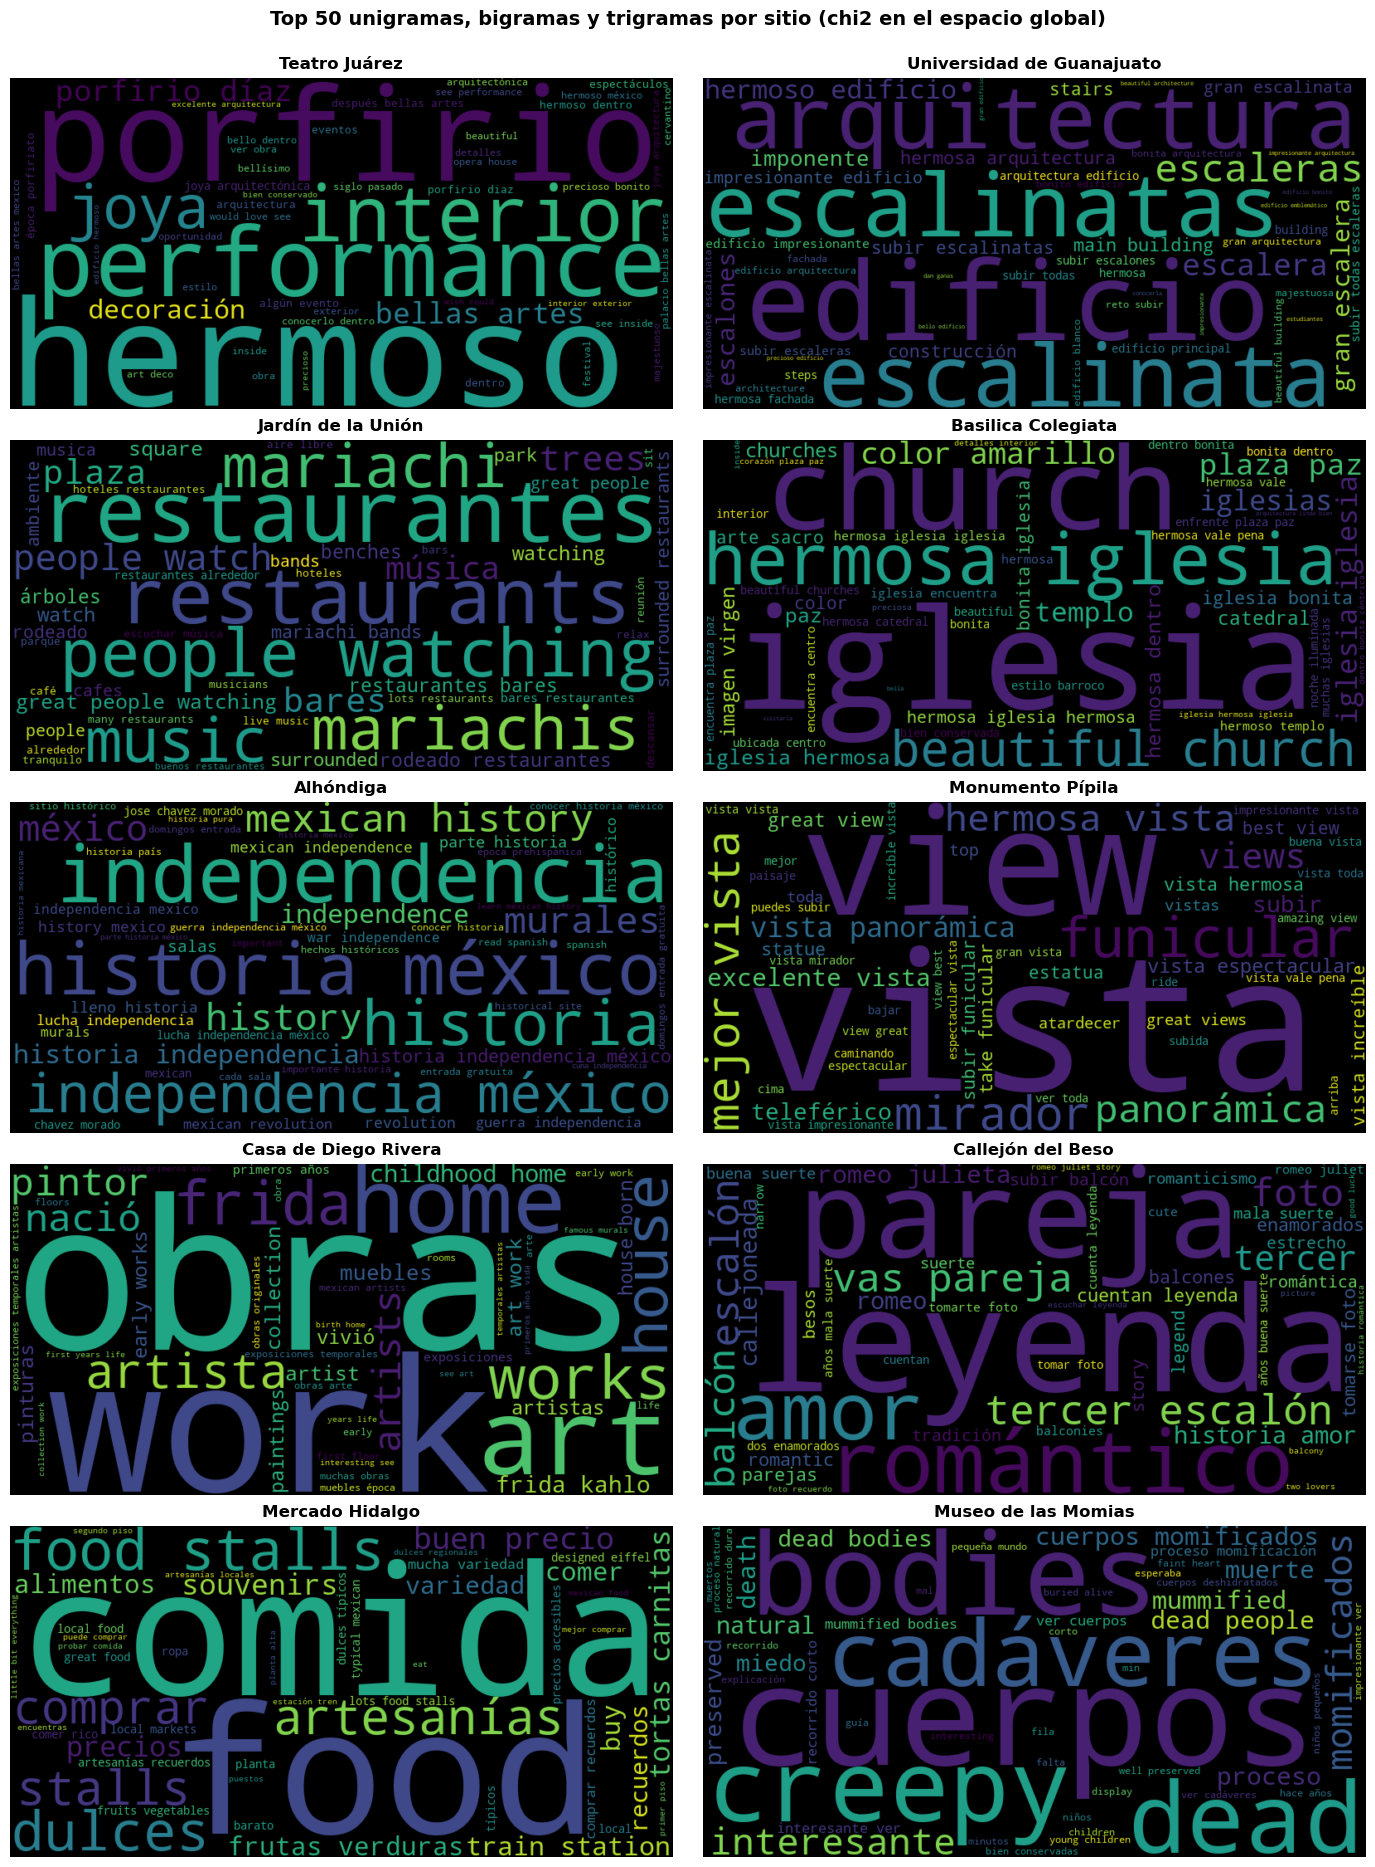

In [141]:
dibujar_nubes(nubes_ngramas, 'Top 50 unigramas, bigramas y trigramas por sitio (chi2 en el espacio global)')

**Observaciones**
- De los 1000 n-gramas seleccionados, casi la mitad son bigramas (493) y solo 115 son trigramas. Los trigramas se repiten poco, por eso entran pocos al top 50 de cada sitio (menos de 10 en todos).
- Los bigramas dan el contexto que le faltaba a las palabras solas: *tercer escalón, romeo julieta, mala suerte* en el Callejón del Beso, *recorrido corto, niños pequeños* en el Museo de las Momias, *buen precio, tortas carnitas* en el Mercado Hidalgo y *entrada gratuita* en la Alhóndiga.
- Algunos bigramas repiten la misma palabra, como *iglesia iglesia*. Eso pasa porque juntamos el título con la opinión, y muchas veces el título termina con la misma palabra con la que empieza la opinión.

---
## Actividad 5. Análisis temporal

Vamos a ver cómo cambian las opiniones positivas, neutras y negativas a través de los meses y los años. Lo hacemos en cuatro partes:

1. Opiniones por año
2. Opiniones por mes, de 2012 a 2018
3. Meses del año: en cuáles hay más opiniones y en cuáles hay más quejas
4. Evolución de cada sitio

In [142]:
# Primero vemos cuántas opiniones hay por año
print(df['Año'].value_counts().sort_index().to_dict())

# Antes de 2012 casi no hay opiniones, así que empezamos en 2012
temporal = df[df['Año'] >= 2012].copy()
temporal['Año_mes'] = temporal['Fecha'].dt.to_period('M')
print('Última opinión:', temporal['Fecha'].max().date())

{2002: 1, 2003: 2, 2004: 5, 2005: 1, 2006: 2, 2007: 3, 2008: 7, 2009: 9, 2010: 24, 2011: 112, 2012: 1095, 2013: 858, 2014: 1030, 2015: 2077, 2016: 2645, 2017: 1963, 2018: 628}
Última opinión: 2018-07-23


**Opiniones por año.** La gráfica muestra el número de opiniones de cada año y la tabla el porcentaje de cada polaridad.
Nota: 2018 solo llega a julio.

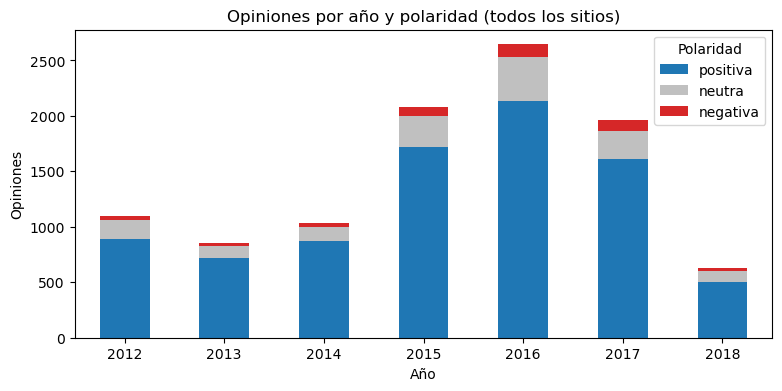

Polaridad,positiva,neutra,negativa,Opiniones
Año,,,,
2012,81.6,15.4,3.0,1095
2013,83.3,13.4,3.3,858
2014,85.0,11.7,3.3,1030
2015,82.8,13.6,3.6,2077
2016,80.9,14.7,4.5,2645
2017,82.1,13.0,4.8,1963
2018,80.3,15.3,4.5,628


In [143]:
# Número de opiniones por año y polaridad, todos los sitios
por_año = pd.crosstab(temporal['Año'], temporal['Polaridad'])[polaridades]

por_año.plot(kind='bar', stacked=True, rot=0, color=colores, figsize=(9, 4))
plt.title('Opiniones por año y polaridad (todos los sitios)')
plt.ylabel('Opiniones')
plt.show()

# La misma tabla en porcentaje
por_año_pct = (pd.crosstab(temporal['Año'], temporal['Polaridad'], normalize='index')[polaridades] * 100).round(1)
por_año_pct['Opiniones'] = por_año.sum(axis=1)
por_año_pct

**Opiniones por mes.** Ahora bajamos al detalle de cada mes, de enero de 2012 a julio de 2018.

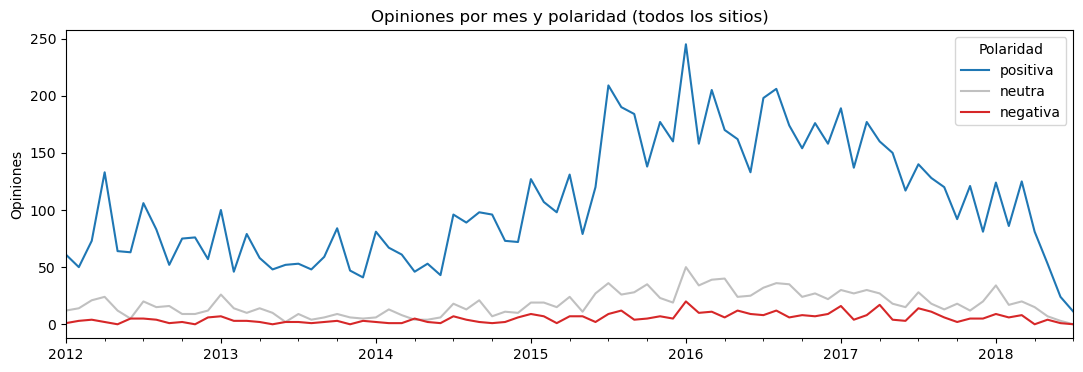

Mes con más opiniones: 2016-01 con 315


In [144]:
# Número de opiniones de cada mes por polaridad
por_mes = pd.crosstab(temporal['Año_mes'], temporal['Polaridad'])[polaridades]

por_mes.plot(color=colores, figsize=(13, 4))
plt.title('Opiniones por mes y polaridad (todos los sitios)')
plt.xlabel('')
plt.ylabel('Opiniones')
plt.show()

print('Mes con más opiniones:', por_mes.sum(axis=1).idxmax(), 'con', por_mes.sum(axis=1).max())

**Meses del año.** Juntamos los años completos (2012 a 2017) para ver si hay meses que se repiten con más opiniones o con más quejas.

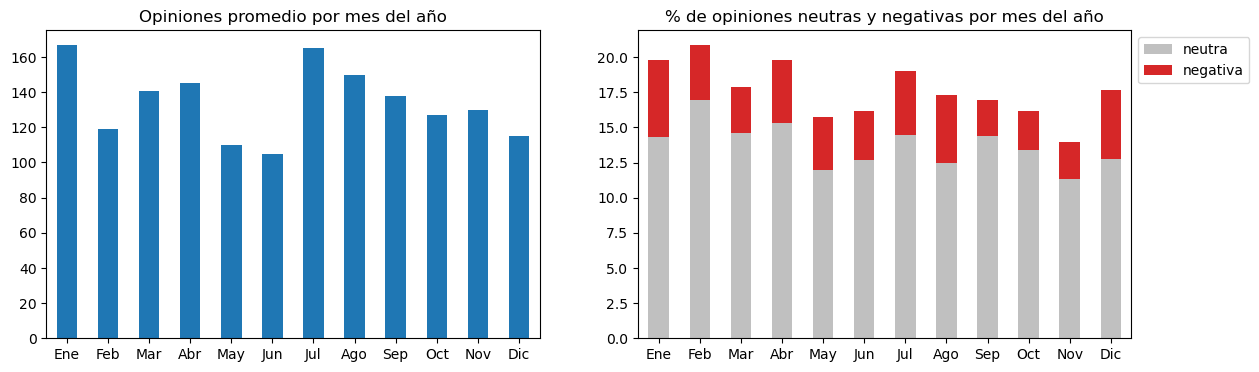

,Ene,Feb,Mar,Abr,May,Jun,Jul,Ago,Sep,Oct,Nov,Dic
Polaridad,,,,,,,,,,,,
positiva,80.2,79.1,82.1,80.2,84.2,83.8,81.0,82.7,83.1,83.9,86.0,82.3
neutra,14.3,16.9,14.6,15.3,12.0,12.7,14.4,12.4,14.4,13.4,11.3,12.7
negativa,5.5,3.9,3.3,4.5,3.8,3.5,4.5,4.9,2.5,2.8,2.7,4.9
Opiniones promedio,166.8,119.0,140.7,145.0,110.0,105.0,165.0,150.0,137.8,127.0,129.8,115.2


In [145]:
# Solo años completos, para que todos los meses pesen igual
completos = temporal[temporal['Año'] <= 2017]

# Opiniones promedio de cada mes y porcentaje de cada polaridad
volumen = completos.groupby('Mes').size() / 6
mes_pct = pd.crosstab(completos['Mes'], completos['Polaridad'], normalize='index')[polaridades] * 100

meses = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']
volumen.index = meses
mes_pct.index = meses

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
volumen.plot(kind='bar', rot=0, ax=axes[0], title='Opiniones promedio por mes del año')
mes_pct[['neutra', 'negativa']].plot(kind='bar', stacked=True, rot=0, color=colores[1:], ax=axes[1],
                                     title='% de opiniones neutras y negativas por mes del año')
axes[1].legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

mes_pct['Opiniones promedio'] = volumen
mes_pct.round(1).T

**Evolución de cada sitio.** Para cada sitio graficamos el porcentaje de opiniones positivas, neutras y negativas de cada año. Dejamos en blanco los años donde el sitio tiene menos de 30 opiniones, porque con tan pocas el porcentaje no es confiable.

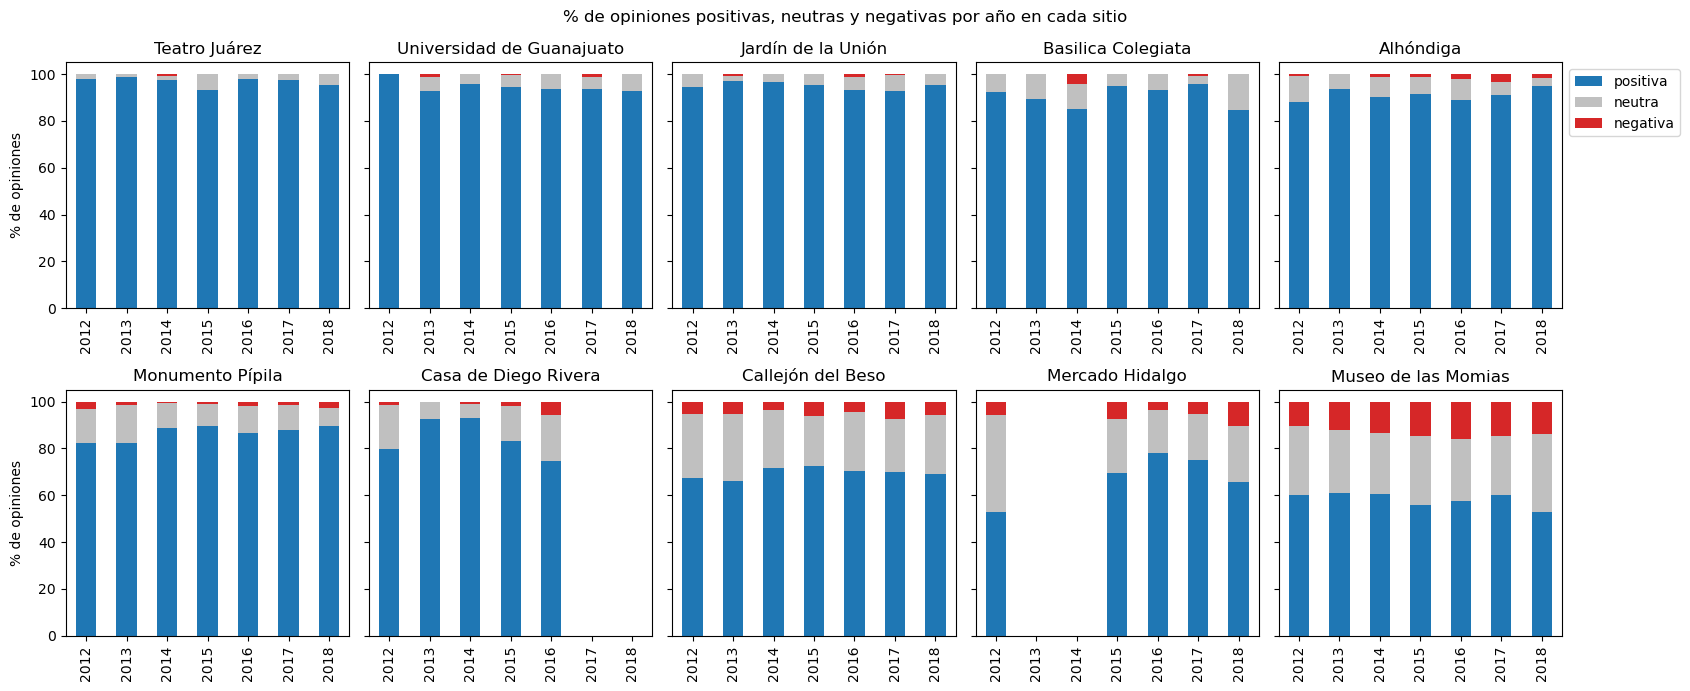

In [146]:
fig, axes = plt.subplots(2, 5, figsize=(17, 7), sharey=True)
for ax, sitio in zip(axes.flat, sitios):
  datos = temporal[temporal['Sitio'] == sitio]
  tabla = pd.crosstab(datos['Año'], datos['Polaridad'], normalize='index').reindex(columns=polaridades, fill_value=0) * 100

  # Nos quedamos con los años que tienen al menos 30 opiniones
  tabla = tabla[datos['Año'].value_counts().sort_index() >= 30]
  tabla = tabla.reindex(range(2012, 2019))

  tabla.plot(kind='bar', stacked=True, color=colores, ax=ax, legend=False, title=sitio)
  ax.set_xlabel('')

axes[0, 0].set_ylabel('% de opiniones')
axes[1, 0].set_ylabel('% de opiniones')
axes[0, 4].legend(loc='upper left', bbox_to_anchor=(1, 1))
fig.suptitle('% de opiniones positivas, neutras y negativas por año en cada sitio')
plt.tight_layout()
plt.show()

**¿Qué sitios mejoraron y cuáles empeoraron?** Comparamos el porcentaje de opiniones no positivas (neutras + negativas) de cada sitio en dos periodos de 3 años: 2012-2014 y 2015-2017.

In [147]:
# Porcentaje de opiniones no positivas de cada sitio en los dos periodos
completos = completos.assign(Periodo=np.where(completos['Año'] <= 2014, '2012-2014', '2015-2017'),
                             No_positiva=completos['Polaridad'] != 'positiva')

cambio = completos.groupby(['Sitio', 'Periodo'])['No_positiva'].mean().unstack() * 100
cambio['Cambio'] = cambio['2015-2017'] - cambio['2012-2014']

# Cambio positivo = el sitio empeoró, cambio negativo = el sitio mejoró
cambio.sort_values('Cambio', ascending=False).round(1)

Periodo,2012-2014,2015-2017,Cambio
Sitio,,,
Casa de Diego Rivera,11.2,19.4,8.2
Museo de las Momias,39.4,42.1,2.7
Universidad de Guanajuato,3.8,6.2,2.4
Jardín de la Unión,4.0,6.3,2.3
Teatro Juárez,2.0,3.4,1.3
Alhóndiga,10.0,9.5,-0.4
Callejón del Beso,31.6,29.2,-2.4
Monumento Pípila,15.7,12.1,-3.5
Basilica Colegiata,10.9,5.7,-5.2


**Observaciones**
- **Por año**: El número de opiniones crece mucho en 2015 y 2016 (2645 opiniones en 2016). El porcentaje de opiniones positivas casi no cambia, se mantiene entre 80% y 85% todos los años. Las negativas suben poco a poco, de 3.0% en 2012 a 4.8% en 2017.
- **Por mes**: El mes con más opiniones es enero de 2016 (315). La caída del final se debe a que los datos de 2018 solo llegan a julio.
- **Meses del año**: Enero y julio son los meses con más opiniones (167 y 165 en promedio), que son meses de vacaciones. Mayo y junio son los más bajos (110 y 105). Febrero tiene el mayor porcentaje de opiniones neutras y negativas (cerca de 21 %) y noviembre el menor (14 %).
- **Por sitio**: En el Museo de las Momias, alrededor de 4 de cada 10 opiniones son neutras o negativas en todos los años. El Callejón del Beso se mantiene cerca de 3 de cada 10.
- **Cambio entre periodos**: La Casa de Diego Rivera es el sitio que más empeoró (de 11.2% a 19.4% de opiniones no positivas). El Mercado Hidalgo es el que más mejoró (de 48.1% a 24.7%), aunque en 2012-2014 solo tiene 104 opiniones.

---
## Preguntas

### 1. ¿De los sitios turísticos, cuál diría usted que es el más polémico y la razón de ello?

El sitio más polémico es el Museo de las Momias.

- Tiene el promedio más bajo (3.68 de 5) y la desviación estándar más alta (1.14). Una desviación alta significa que los turistas no se ponen de acuerdo: unos le ponen 5 y otros 1 o 2. En el Teatro Juárez la desviación es de 0.52 y casi todos opinan lo mismo.

- El 58.5% de sus opiniones son positivas, el 27.2% son neutras y el 14.4% son negativas. Algo interesante de observar es que de 2012 a 2018, alrededor de 4 de cada 10 opiniones del museo son neutras o negativas.

- En las nubes aparece *interesante* junto a *creepy, miedo, morbo* y *macabro*. Lo mismo que a unos turistas les atrae, a otros les incomoda, sobre todo los cuerpos de niños y bebés (*niños pequeños, babies*). También hay quejas del servicio: la *fila*, el *recorrido corto* y la *falta* de *explicación*. Sus opiniones son las más largas de todos los sitios, 58 palabras en promedio, y lo más probable es porque la gente explica por qué le gustó o por qué no.

### 2. En cuanto al sitio más polémico, ¿cómo es la diferencia de opinión y temas entre turistas nacionales e internacionales?

In [148]:
# Polaridad del Museo de las Momias para turistas nacionales e internacionales
momias = df[df['Sitio'] == 'Museo de las Momias']
(pd.crosstab(momias['Origen'], momias['Polaridad'], normalize='index')[polaridades] * 100).round(1)

Polaridad,positiva,neutra,negativa
Origen,,,
Internacional,61.3,24.1,14.6
Nacional,55.8,30.0,14.1


En la calificación casi no hay diferencia. El porcentaje de opiniones negativas es casi igual: 14.1% en nacionales y 14.6% en internacionales. Lo que cambia son las opiniones neutras: 30% en nacionales contra 24.1% en internacionales. Los nacionales salen menos convencidos.

La diferencia grande está en los temas, es decir, en los tópicos de LSA los nacionales hablan de cómo fue la visita: *fila, temporada alta, horas, guía, recorrido* y *explicación*. Podemos observar que su queja es de servicio, por ejemplo, esperar mucho para un recorrido que les parece corto o con poca información.

Por otro lado, los internacionales hablan de lo que se exhibe: *creepy, dead, preserved, babies, burial, buried, soil* y *families*. Les llama la atención que los cuerpos sean reales, cómo se conservaron al estar enterrados y que entre ellos haya bebés. Para ellos el museo es algo extraño, que a unos les fascina y a otros les incomoda.

En resumen, los dos grupos califican casi igual, pero por razones diferentes. Nuestra lectura es que el turista nacional ya sabe a qué va y juzga la organización de la visita, mientras que el internacional se encuentra con algo que no esperaba y juzga la exhibición misma. Hay que tomar en cuenta que LSA separa los tópicos por idioma, así que parte de la diferencia viene de que los internacionales escriben más en inglés.

### 3. ¿Cuál diría que es el sitio que le gusta más a las mujeres y por qué?

El sitio que más les gusta a las mujeres es el Teatro Juárez. Para contestar esta pregunta, usamos la calificación promedio que le dieron las mujeres a cada sitio.

El Teatro Juárez tiene el promedio más alto entre las mujeres: 4.73 de 5, con 456 opiniones. Después, le siguen la Universidad de Guanajuato (4.64) y el Jardín de la Unión (4.62). El que menos les gusta es el Museo de las Momias (3.69).

Los tópicos de LSA nos dicen por qué, observamos que cuando las mujeres hablan del teatro usan palabras como *hermoso, arquitectura, interior, bello, impresionante* e *iluminación*, y en inglés *beautiful, inside* y *performance*. Lo que les gusta es el edificio, sobre todo por dentro, cómo se ve iluminado de noche y la experiencia de ver una función ahí.

Aunque tenemos otro dato interesante el Teatro Juárez también es el favorito de los hombres (4.68), así que no es un gusto solo de las mujeres. Si buscamos el sitio donde las mujeres califican más alto que los hombres, ese es la Basílica Colegiata: ellas le dan 4.58 y ellos 4.44. Es la diferencia más grande de los 10 sitios.
Entonces, el sitio que más les gusta a las mujeres es el Teatro Juárez, y el sitio que les gusta más a ellas que a ellos es la Basílica.

### 4. ¿Cuál diría que es el sitio que le gusta más a las personas jóvenes y por qué?

El sitio que más les gusta a los jóvenes también es el Teatro Juárez. Consideramos jóvenes a los turistas de 15 a 29 años, que son 2537 opiniones.

Los jóvenes le dan al Teatro Juárez un promedio de 4.75 de 5, el más alto de los 10 sitios, con 212 opiniones. En segundo lugar está la Universidad de Guanajuato (4.65), que además es uno de los sitios con más visitantes jóvenes (29%).

En los tópicos de LSA, los jóvenes hablan del teatro con palabras como *hermoso, arquitectura, dentro* y *noche*, y también aparecen *escuchar, historias* y *restaurantes*. Esto nos dice que no solo les gusta el edificio, sino el ambiente que hay alrededor en la noche.

Ahora bien, el Teatro Juárez les gusta a todos los grupos. Si buscamos un sitio que los jóvenes disfruten más que los demás, ese es el Callejón del Beso. Los jóvenes le dan 4.09, contra 4.00 del promedio general y 4.01 de los mayores. También es el sitio con mayor proporción de jóvenes (29.3%). En sus tópicos aparecen *pareja, leyenda, foto* y *romántico*: van en pareja, escuchan la leyenda y se toman la foto. Nuestra lectura es que lo que a otros turistas les parece solo un callejón angosto, para un joven es una experiencia.

En resumen, el mejor calificado por los jóvenes es el Teatro Juárez, y el que disfrutan más que los demás es el Callejón del Beso.

### 5. ¿Qué otras observaciones valiosas puede obtener de su análisis?

El idioma porque cerca de 3 de cada 10 opiniones están en inglés, y LSA separó un tópico para el español y otro para el inglés en casi todos los grupos. Cuando hay dos idiomas, el idioma se vuelve un tema por sí mismo y hay que leer los tópicos con cuidado.

Los bigramas explican lo que las palabras solas no dicen. *Tercer escalón* y *mala suerte* cuentan la leyenda del Callejón del Beso, *domingos entrada gratuita* nos dice que la Alhóndiga no cobra los domingos.

Las opiniones siguen las vacaciones, por ejemplo, enero y julio son los meses con más opiniones. Febrero tiene el mayor porcentaje de opiniones neutras y negativas (cerca de 21%) y noviembre el menor (14%).

Por último, muchas quejas son de servicio y no del sitio: la fila, el recorrido corto y la falta de explicación en el Museo de las Momias. Esas sí se pueden atender, y un análisis como este ayuda a encontrarlas.